In [5]:
import qiskit
from qiskit.providers.aer.noise import NoiseModel, ReadoutError
from qiskit.providers.aer.noise.errors import pauli_error
from qiskit import QuantumCircuit, execute, Aer
from qiskit.result import Result
from qiskit.quantum_info import state_fidelity, DensityMatrix
from qiskit_ibm_runtime import QiskitRuntimeService
from FiveQubitCode import FiveQubitCode

import numpy as np

### Simulator Configuration

In [6]:
# service = QiskitRuntimeService()
simulator = Aer.get_backend('aer_simulator_density_matrix')
# simulator = service.get_backend('ibmq_qasm_simulator')
# simulator.set_options(method='density_matrix')
shots = 2**10

# Labels for density matrix snapshots
rho_sim_labels = ['init_data',
                  'init_logical',
                  'pre_decode_logical',
                  'final_data',
                  'final_logical']

### Utility Functions

In [7]:
def two_param_meas_error(eff: float, dc: float, atol: float=1e-8) -> ReadoutError:
    """Construct Qiskit measurement error model using detection and dark count probabilities

    :param eff: Detection probability. Probability of measuring 1 if 1 is true measurement
    :type eff: float
    :param dc: Dark count probability. Probability of measuring 1 if 0 is true measurement
    :type dc: float
    :param atol: tolerance, defaults to 1e-8
    :type atol: float, optional
    :return: Measurement error model
    :rtype: ReadoutError
    """
    return ReadoutError([[1-dc,  dc],  #[P(0|0), P(1|0)]
                         [1-eff, eff]] #[P(0|1), P(1|1)]
                         ,atol) 


def two_param_pauli_error(pX: float, pZ: float) -> pauli_error:
    """Construct a quantum Pauli error channel 
    composed of a bit-flip (X) and phase-flip (Z) 
    channel with their respective probabilities

    :param pX: Bit flip probability
    :type pX: float
    :param pZ: Phase flip probability
    :type pZ: float
    :return: Pauli error model
    :rtype: pauli_error
    """
    x_error = pauli_error([('X',pX),('I',1-pX)])
    z_error = pauli_error([('Z',pZ),('I',1-pZ)])

    return x_error.compose(z_error)

def circuit_init(init_state: str='+') -> QuantumCircuit:
    q_reg = FiveQubitCode.q_reg
    a_reg = FiveQubitCode.a_reg
    c_reg = FiveQubitCode.c_reg

    circ_enc = FiveQubitCode.encoder()

    qcirc = QuantumCircuit(q_reg,a_reg,c_reg)
    
    qcirc.initialize(init_state+'0'*4,qcirc.qregs[0])
    qcirc.save_density_matrix([qcirc.qregs[0][4]],label=rho_sim_labels[0])
    qcirc.compose(circ_enc,inplace=True)
    qcirc.save_density_matrix(qcirc.qregs[0],label=rho_sim_labels[1])

    return qcirc

def circuit_end() -> QuantumCircuit:
    q_reg = FiveQubitCode.q_reg
    a_reg = FiveQubitCode.a_reg
    c_reg = FiveQubitCode.c_reg

    circ_dec = FiveQubitCode.decoder()

    qcirc = QuantumCircuit(q_reg,a_reg,c_reg)
    qcirc.save_density_matrix(qcirc.qregs[0],label=rho_sim_labels[2])
    qcirc.compose(circ_dec, inplace=True)
    qcirc.save_density_matrix([qcirc.qregs[0][4]],label=rho_sim_labels[3])
    qcirc.save_density_matrix(qcirc.qregs[0],label=rho_sim_labels[4])
    return qcirc

def circuit_QEC(steps: int = 100, qec_period: int = 1) -> QuantumCircuit:
    """_summary_

    :param steps: Total number of error channel steps to perform, defaults to 100
    :type steps: int, optional
    :param qec_period: Error steps to wait before performing error correction, defaults to 1; Must be evenly divide :param steps:
    :type qec_period: int, optional
    :raises ValueError: Error steps must be divisible by error correcting period
    :return: Subcircuit to apply and correct errors to a 5-qubit code logical state
    :rtype: QuantumCircuit
    """
    num_reps = steps // qec_period
    extra = steps % qec_period
    if extra:
        raise ValueError('Error steps must be divisible by error correcting period.')

    q_reg = FiveQubitCode.q_reg
    a_reg = FiveQubitCode.a_reg
    c_reg = FiveQubitCode.c_reg

    circ_meas = FiveQubitCode.stab_meas()
    circ_correct = FiveQubitCode.err_correct()

    delay_circ = QuantumCircuit(q_reg,a_reg,c_reg,name='Noisy Delay')
    # delay_circ.delay(1,delay_circ.qregs[0])
    delay_circ.id(delay_circ.qregs[0])
    delay_circ = delay_circ.repeat(qec_period)
    delay_circ.barrier()

    qcirc = circ_meas
    # qcirc.compose(delay_circ, qcirc.qregs[0][:5],front=True,inplace=True)
    qcirc.compose(delay_circ,front=True,inplace=True)
    qcirc.barrier()
    qcirc.compose(circ_correct, inplace=True)
    qcirc.barrier()

    qcirc = qcirc.repeat(num_reps)
    qcirc.name = 'Error & Correction'
    return qcirc

def get_noise(meas_error: list|NoiseModel, quantum_error: list|NoiseModel) -> NoiseModel:
    """Construct a noise model containing measurement errors and noisy quantum delay gates on all qubits.

    :param meas_error: A list of form [Eff, DC] where Eff is the detection efficiency and DC is the dark count probability. 
                       Alternatively specify a pre-instantiated ReadoutError object
    :type meas_error: list | NoiseModel
    :param quantum_error: A list of form [pX, pZ] where pX and pZ are respectively the bit and phase flip channel probabilities.
                       Alternatively specify a pre-instantiated QuantumError object
    :type quantum_error: list | NoiseModel
    :return: Noise model where the specified errors are applied to all measurements and all qubits via the 'delay' gate.
    :rtype: NoiseModel
    """
    if type(meas_error) == list:
        meas_error = two_param_meas_error(*meas_error)
    if type(quantum_error) == list:
        quantum_error = two_param_pauli_error(*quantum_error)
    
    noise_model = NoiseModel()
    noise_model.add_all_qubit_readout_error(meas_error)
    noise_model.add_all_qubit_quantum_error(quantum_error, ['i','id','delay'])

    return noise_model

def get_density_matrix(res: Result,key: str) -> DensityMatrix:
    return res.results[0].data.__dict__[key]

### Simulation Validation

Construct circuit

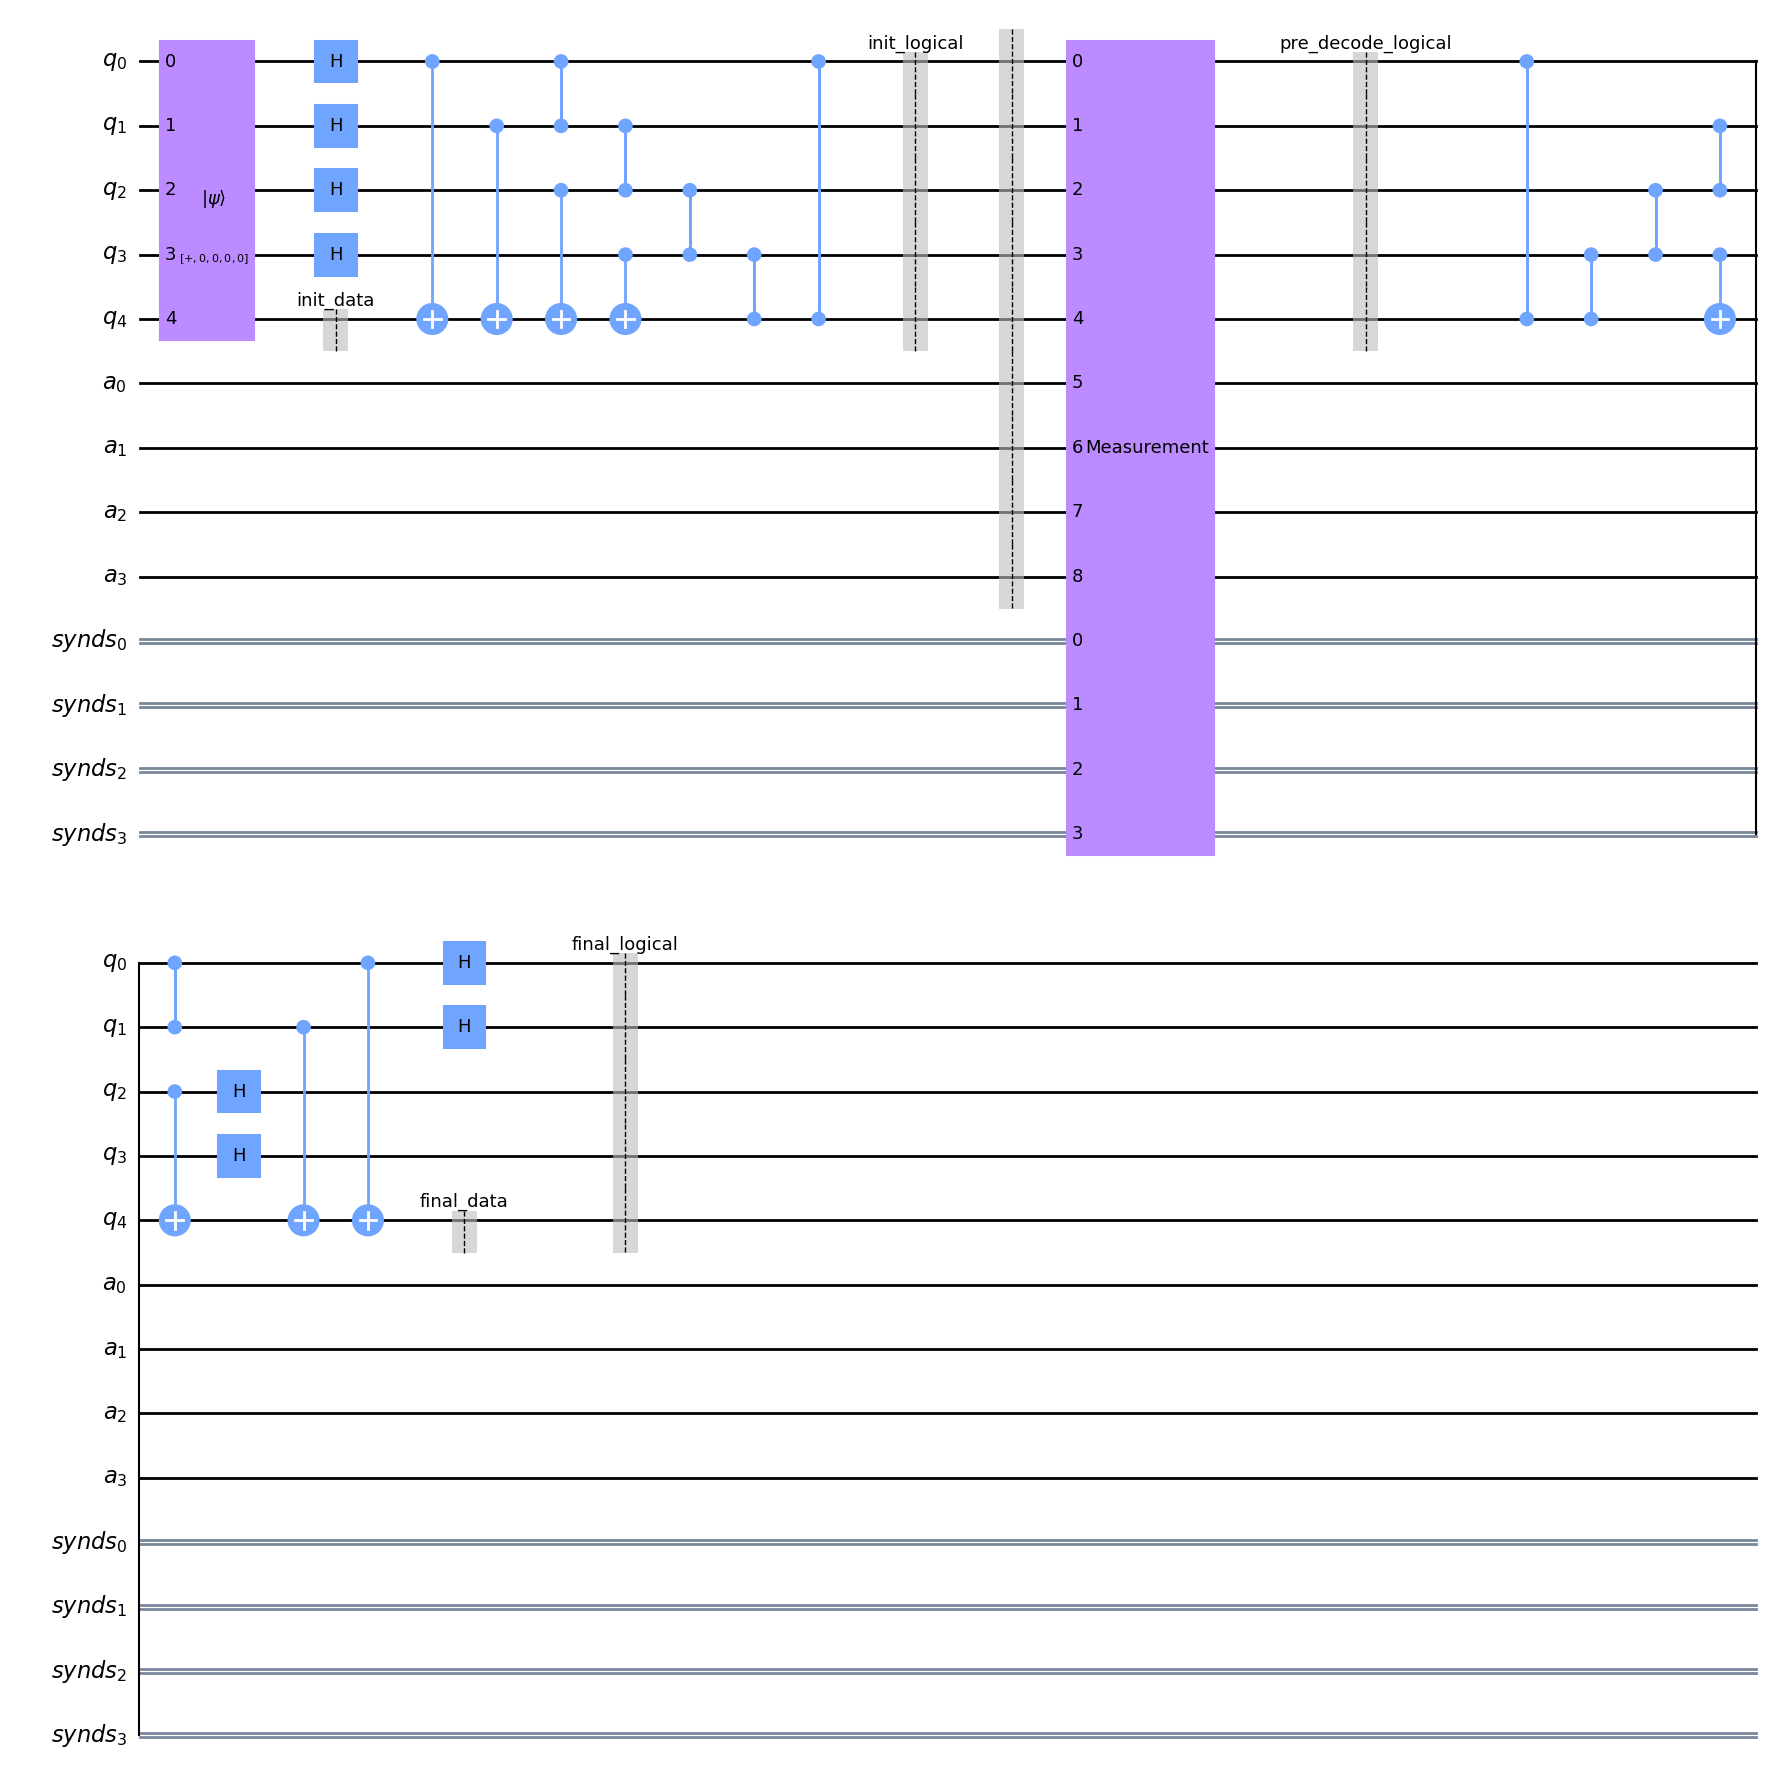

In [8]:
q_reg = FiveQubitCode.q_reg
a_reg = FiveQubitCode.a_reg
c_reg = FiveQubitCode.c_reg

qcirc = QuantumCircuit(q_reg, a_reg, c_reg)
qcirc.compose(circuit_init('+'), inplace=True)
# qcirc.delay(1,qcirc.qregs[0])
qcirc.barrier()
qcirc.compose(circuit_QEC(steps=1,qec_period=1), inplace=True)
qcirc.compose(circuit_end(), inplace=True)

qcirc.draw(output='mpl')

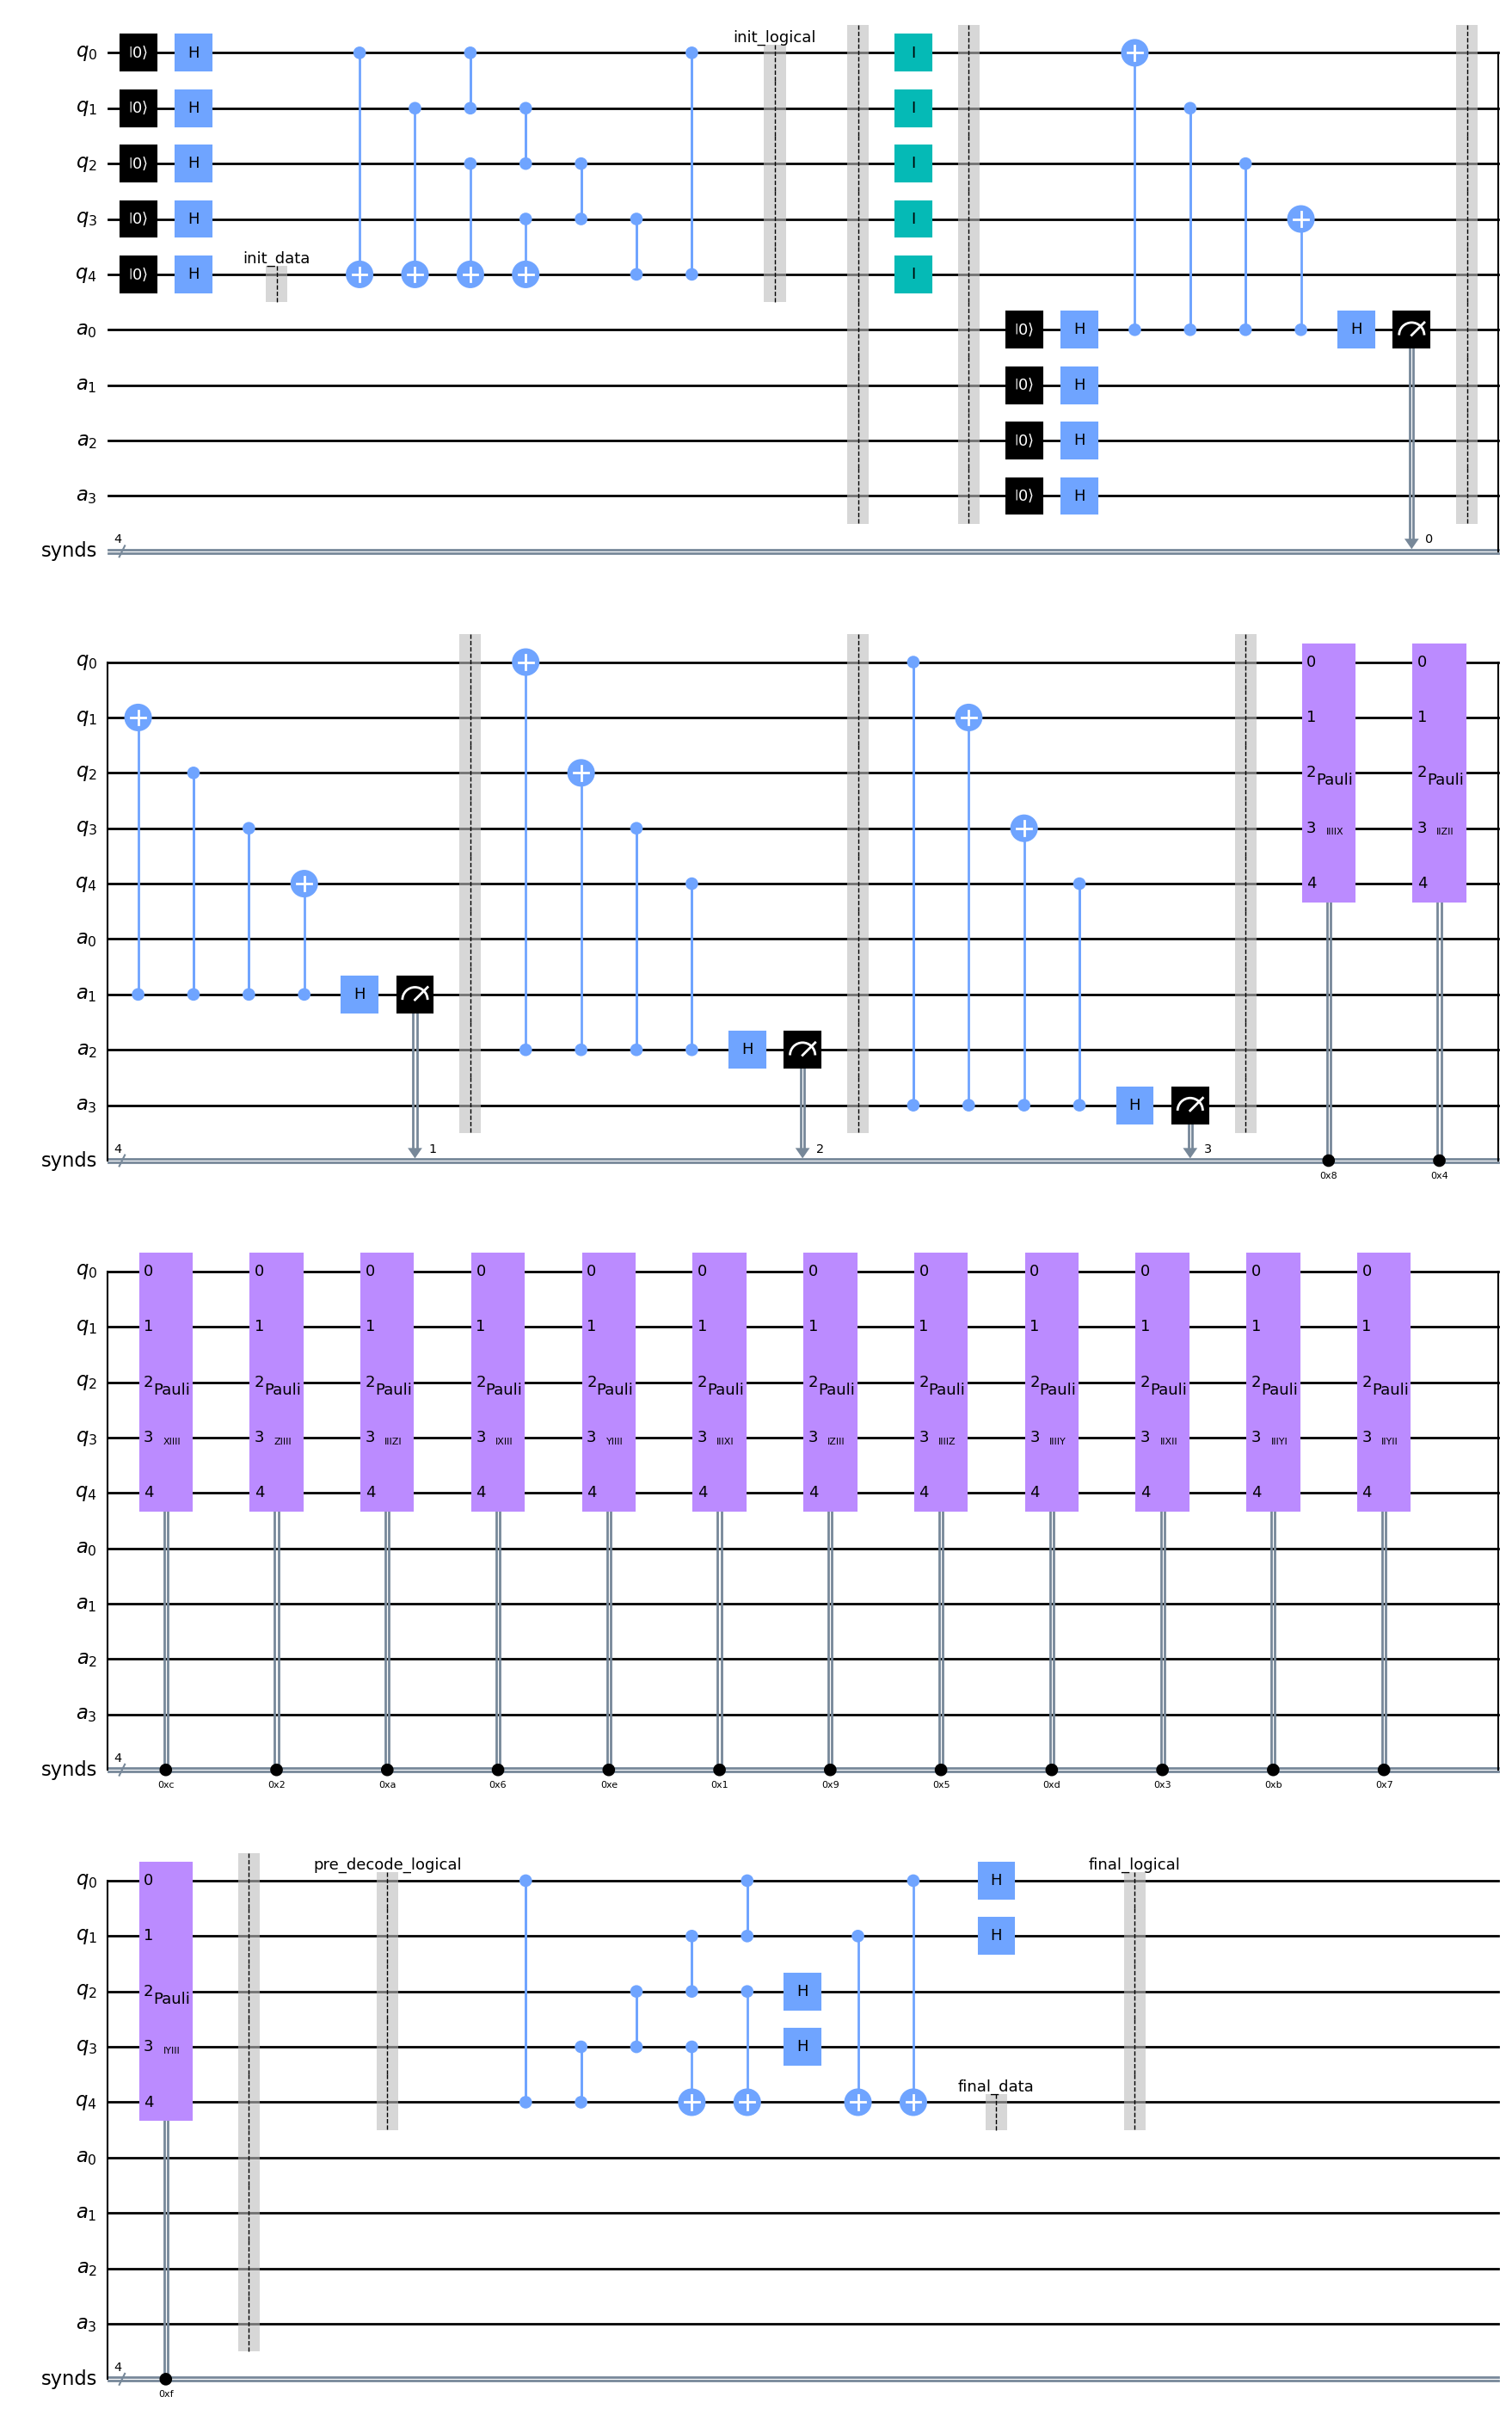

In [9]:
# run the circuit with the noise model and extract the counts
# Simulator backend to use
noise_model = get_noise(meas_error=[1,0], quantum_error=[0.5,0.5])

T_qcirc = qiskit.transpile(qcirc,simulator,optimization_level=0)
T_qcirc.draw(output='mpl')

In [10]:
res = simulator.run(T_qcirc,noise_model=noise_model,shots=2**9).result()
# res = execute(qcirc,simulator,noise_model=noise_model,shots=2**9).result()

In [11]:
data_rho_init = get_density_matrix(res,'init_data')
data_rho_final = get_density_matrix(res,'final_data')

logical_rho_init = get_density_matrix(res,'init_logical')
logical_rho_final = get_density_matrix(res,'final_logical')

rho_pre_decode = get_density_matrix(res,'pre_decode_logical')

print(state_fidelity(data_rho_init,data_rho_final))
print(state_fidelity(logical_rho_init,logical_rho_final))
print(state_fidelity(logical_rho_init,rho_pre_decode))

print(data_rho_init,data_rho_final,sep='\n')

0.5000000062651667
0.03125000215851996
0.5000000098416989
DensityMatrix([[0.5+0.j, 0.5+0.j],
               [0.5+0.j, 0.5+0.j]],
              dims=(2,))
DensityMatrix([[0.5+0.j, 0. +0.j],
               [0. +0.j, 0.5+0.j]],
              dims=(2,))


## Single-step Simulation
Simulate circuit with only a single cycle of error and correction

### Circuit Construction

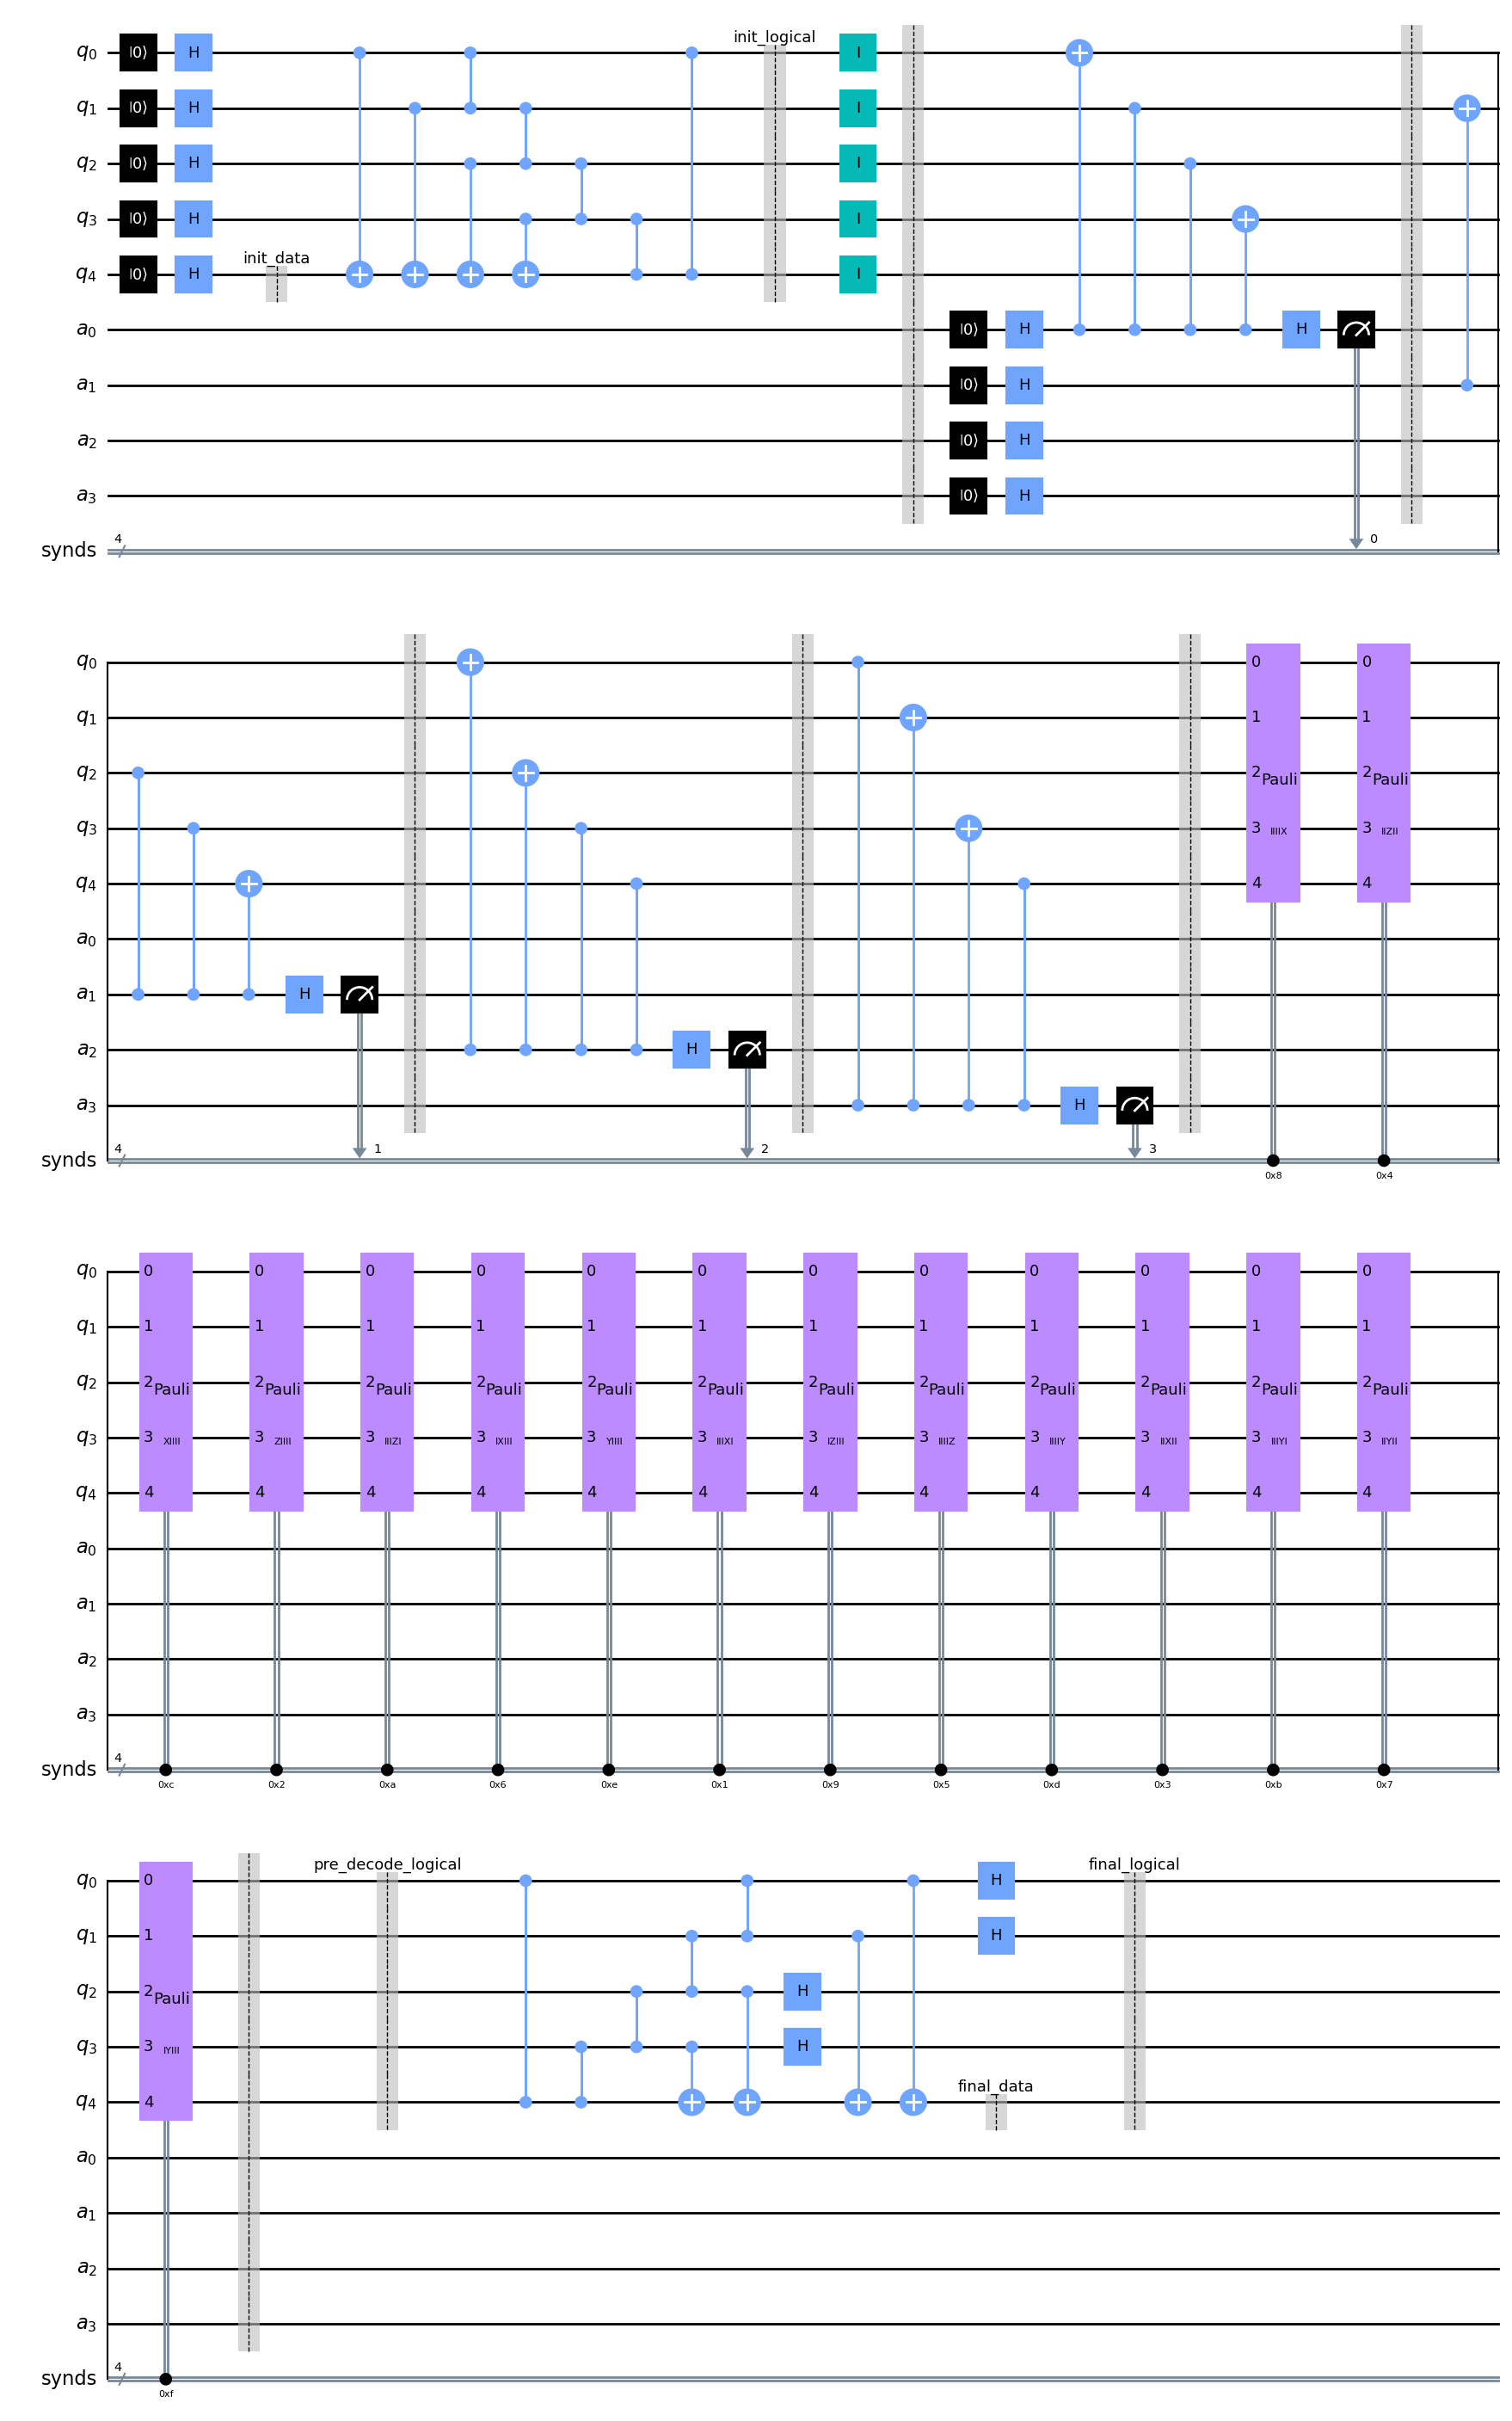

In [17]:
q_reg = FiveQubitCode.q_reg
a_reg = FiveQubitCode.a_reg
c_reg = FiveQubitCode.c_reg

qcirc_single_step = QuantumCircuit(q_reg, a_reg, c_reg)
qcirc_single_step.compose(circuit_init('+'), inplace=True)
qcirc_single_step.compose(circuit_QEC(steps=1,qec_period=1),inplace=True)
qcirc_single_step.compose(circuit_end(), inplace=True)

T_qcirc_single_step = qiskit.transpile(qcirc_single_step,simulator,optimization_level=0)
T_qcirc_single_step.draw(output='mpl')

### Quantum Error Parameter Sweep

In [ ]:
qerr_sweep_datafile = './qerr_single_step_sweep'

pXs = np.append(np.float_power(10,np.arange(-3,0)),np.arange(0.125,1.125,0.125))
pXs.put(0,0)
pZs = pXs

# initialize fidelity matrix 
fids = np.empty([pXs.size,pZs.size])
fids.fill(np.nan)

# initialize NPZ archive file
np.savez(qerr_sweep_datafile,row_data=pXs,col_data=pZs,fids=fids)

for (x,px) in enumerate(pXs):
    for (z,pz) in enumerate(pZs):
        print(f"Sim {x*pXs.size + z + 1}/{fids.size}")

        noise_model = get_noise(meas_error=[1,0], quantum_error=[px,pz])
        res = simulator.run(T_qcirc_single_step,noise_model=noise_model,shots=shots).result()
        
        # Get initial and final logical matrix
        rho_logical_i = get_density_matrix(res,rho_sim_labels[1])
        rho_logical_f = get_density_matrix(res,rho_sim_labels[-3])

        # Calculate fidelity and save to file
        fids[x,z] = state_fidelity(rho_logical_i,rho_logical_f)
        np.savez(qerr_sweep_datafile,row_data=pXs,col_data=pZs,fids=fids)



### Measurement Efficiency Sweep

In [ ]:
eff_sweep_datafile = './eff_single_step_sweep'

# Quantum error channel parameter sweep
pXs = np.append(np.float_power(10,np.arange(-3,0)),np.arange(0.125,1.125,0.125))
pXs.put(0,0)
effs = np.append(np.float_power(10,np.arange(-3,0)),np.arange(0.125,1.125,0.125))
effs.put(0,0)

fids = np.zeros([pXs.size,effs.size])

for (x,px) in enumerate(pXs):
    for (e,eff) in enumerate(effs):
        print(f"Sim {x*pXs.size + e + 1}/{fids.size}")

        noise_model = get_noise(meas_error=[eff,0], quantum_error=[px]*2)
        res = simulator.run(T_qcirc_single_step,noise_model=noise_model,shots=shots).result()
        
        # Get initial and final logical matrix
        rho_logical_i = get_density_matrix(res,rho_sim_labels[1])
        rho_logical_f = get_density_matrix(res,rho_sim_labels[-3])

        fids[x,e] = state_fidelity(rho_logical_i,rho_logical_f)
        np.savez(eff_sweep_datafile,row_data=pXs,col_data=effs,fids=fids)



### Measurement Dark Count Sweep

In [ ]:
dc_sweep_datafile = './dc_single_step_sweep'
# Quantum error channel parameter sweep
pXs = np.append(np.float_power(10,np.arange(-3,0)),np.arange(0.125,1.125,0.125))
pXs.put(0,0)
dcs = pXs

fids = np.zeros([pXs.size,dcs.size])

for (x,px) in enumerate(pXs):
    for (d,dc) in enumerate(dcs):
        print(f"Sim {x*pXs.size + d + 1}/{fids.size}")

        noise_model = get_noise(meas_error=[1,dc], meas_=[px]*2)
        res = simulator.run(T_qcirc_single_step,noise_model=noise_model,shots=shots).result()
        
        # Get initial and final logical matrix
        rho_logical_i = get_density_matrix(res,rho_sim_labels[1])
        rho_logical_f = get_density_matrix(res,rho_sim_labels[-3])

        fids[x,d] = state_fidelity(rho_logical_i,rho_logical_f)
        np.savez(dc_sweep_datafile,row_data=pXs,col_data=dcs,fids=fids)

